# Netflix Titles — Exploratory Data Analysis (EDA)

**Task 2 | Dataset:** `netflix_titles_cleaned.csv`

## Objective
Explore Netflix titles to understand the catalogue mix, release patterns, content ratings, country representation and title duration. Identify trends, unusual values and actionable observations.

## Tools
Python, Pandas, NumPy, Matplotlib and Seaborn.

> Run this notebook from the same folder as `netflix_titles_cleaned.csv`. The dataset is included in this project folder.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("netflix_titles_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (8807, 15)


,show_id,type,title,director,cast,country,date_added,year_added,month_added,release_year,rating,duration_value,duration_unit,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2021.0,September,2020,PG-13,90,min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021.0,September,2021,TV-MA,2,Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021.0,September,2021,TV-MA,1,Seasons,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021.0,September,2021,TV-MA,1,Seasons,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021.0,September,2021,TV-MA,2,Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 1. Data understanding

In [2]:
df.info()
display(df.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   show_id         8807 non-null   str    
 1   type            8807 non-null   str    
 2   title           8807 non-null   str    
 3   director        8807 non-null   str    
 4   cast            8807 non-null   str    
 5   country         8807 non-null   str    
 6   date_added      8797 non-null   str    
 7   year_added      8797 non-null   float64
 8   month_added     8797 non-null   str    
 9   release_year    8807 non-null   int64  
 10  rating          8807 non-null   str    
 11  duration_value  8807 non-null   int64  
 12  duration_unit   8807 non-null   str    
 13  listed_in       8807 non-null   str    
 14  description     8807 non-null   str    
dtypes: float64(1), int64(2), str(12)
memory usage: 1.0 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8806,Consequences,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8807,4529,Unknown,2634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,8807,7693,Unknown,825,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8807,744,United States,2819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1714,2020-01-01,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_added,8797.0,NaN,NaN,NaN,2018.871888,1.574243,2008.0,2018.0,2019.0,2020.0,2021.0
month_added,8797,12,July,827,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0


## 2. Data quality checks

In [3]:
print("Duplicate rows:", df.duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_values"))

# 'Unknown' is a text placeholder in some columns, not a true pandas null.
for col in ["director", "cast", "country", "rating"]:
    print(f"{col}: {(df[col].astype(str).str.strip().str.lower() == 'unknown').sum()} rows marked Unknown")


Duplicate rows: 0


,missing_values
date_added,10
month_added,10
year_added,10


director: 2634 rows marked Unknown
cast: 825 rows marked Unknown
country: 831 rows marked Unknown
rating: 7 rows marked Unknown


## 3. Univariate analysis

,count,percentage
type,,
Movie,6131,69.6
TV Show,2676,30.4


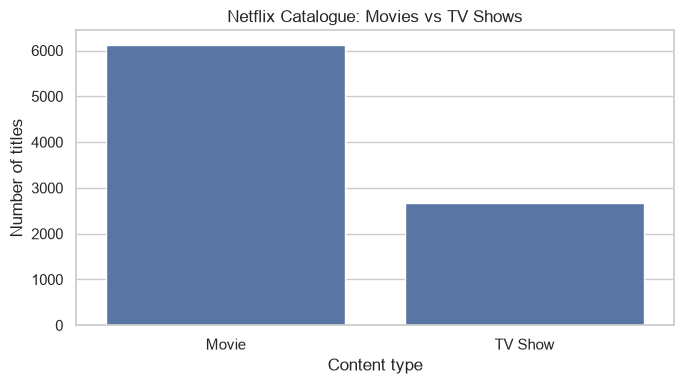

In [4]:
type_counts = df["type"].value_counts()
display(pd.DataFrame({"count": type_counts, "percentage": (type_counts / len(df) * 100).round(1)}))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="type", order=type_counts.index)
plt.title("Netflix Catalogue: Movies vs TV Shows")
plt.xlabel("Content type"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()


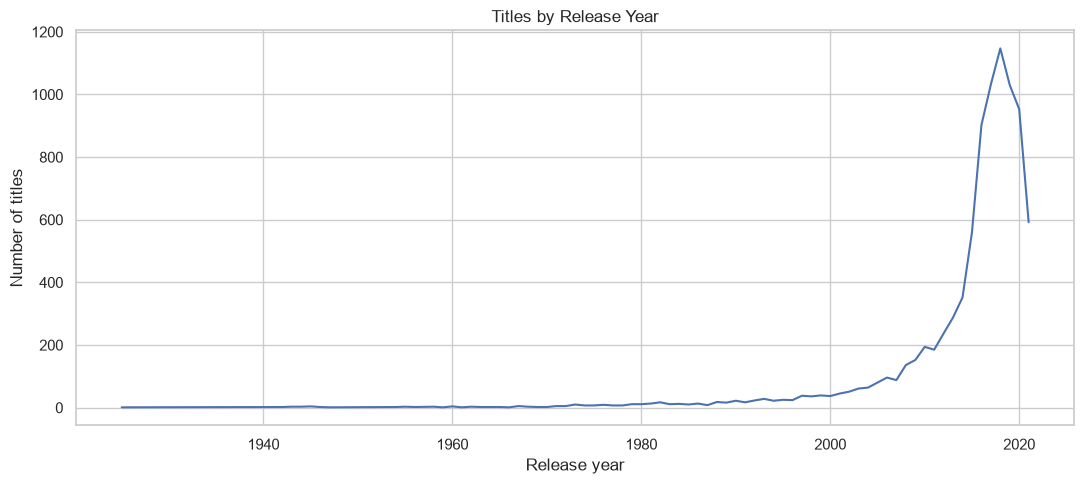

In [5]:
plt.figure(figsize=(11, 5))
year_counts = df["release_year"].value_counts().sort_index()
plt.plot(year_counts.index, year_counts.values)
plt.title("Titles by Release Year")
plt.xlabel("Release year"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()


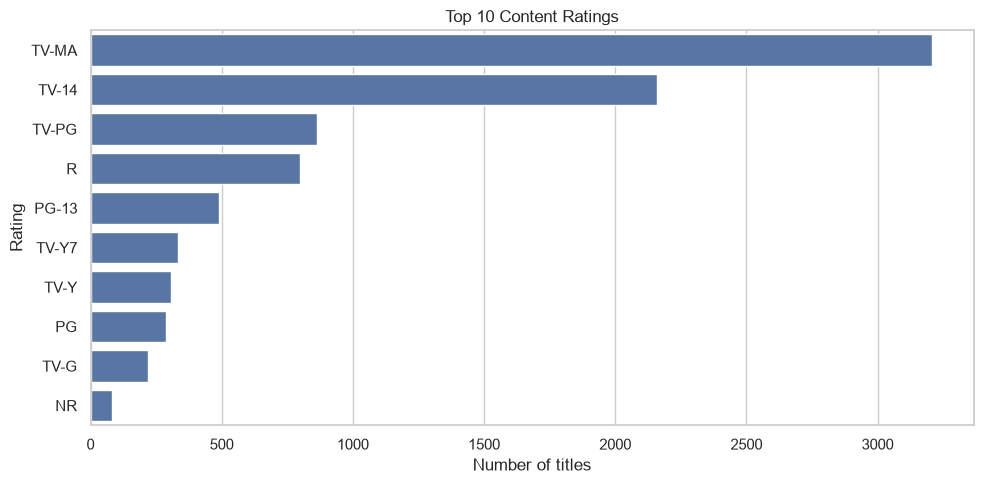

In [6]:
plt.figure(figsize=(10, 5))
top_ratings = df["rating"].value_counts().head(10)
sns.barplot(x=top_ratings.values, y=top_ratings.index)
plt.title("Top 10 Content Ratings")
plt.xlabel("Number of titles"); plt.ylabel("Rating")
plt.tight_layout(); plt.show()


## 4. Country and addition trends

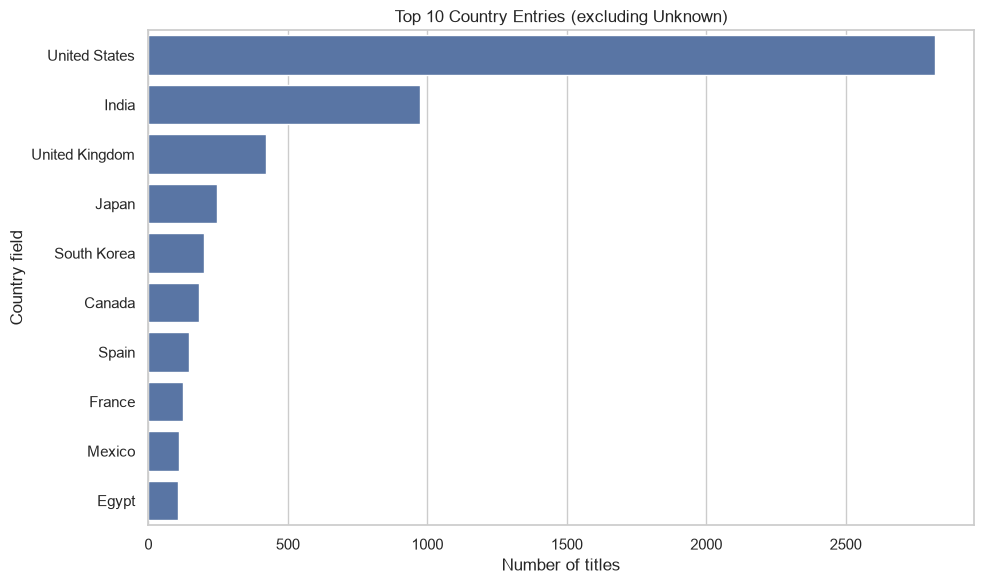

In [7]:
# Country values can contain multiple countries in one cell. This chart counts
# the raw country field as stored; it does not split co-productions into countries.
top_countries = df.loc[df["country"].ne("Unknown"), "country"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Country Entries (excluding Unknown)")
plt.xlabel("Number of titles"); plt.ylabel("Country field")
plt.tight_layout(); plt.show()


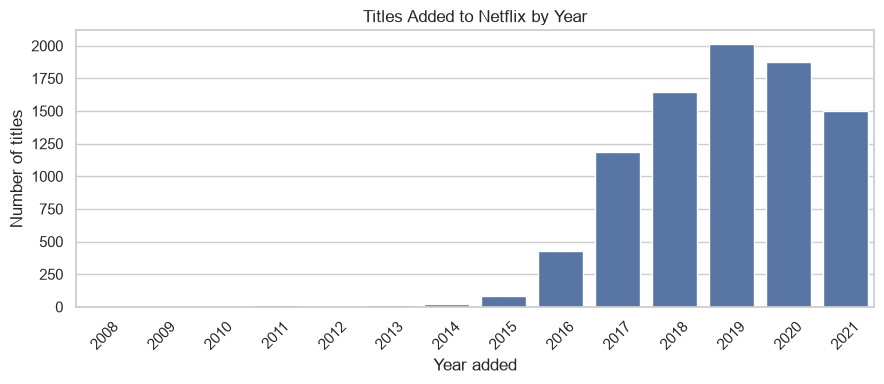

In [8]:
year_added = df["year_added"].dropna().astype(int).value_counts().sort_index()
plt.figure(figsize=(9, 4))
sns.barplot(x=year_added.index.astype(str), y=year_added.values)
plt.title("Titles Added to Netflix by Year")
plt.xlabel("Year added"); plt.ylabel("Number of titles")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


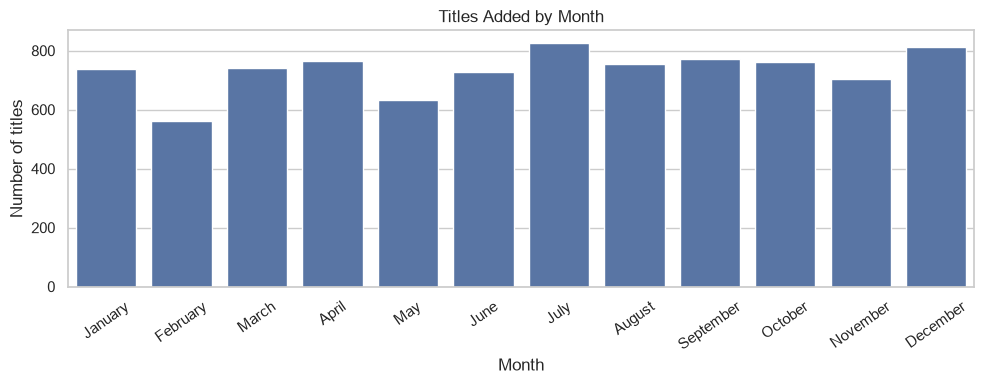

In [9]:
month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]
month_counts = df["month_added"].value_counts().reindex(month_order)
plt.figure(figsize=(10, 4))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title("Titles Added by Month")
plt.xlabel("Month"); plt.ylabel("Number of titles")
plt.xticks(rotation=35); plt.tight_layout(); plt.show()


## 5. Duration analysis and anomaly checks

Movie duration (minutes) — descriptive statistics


count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

TV show seasons — descriptive statistics


count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_value, dtype: float64

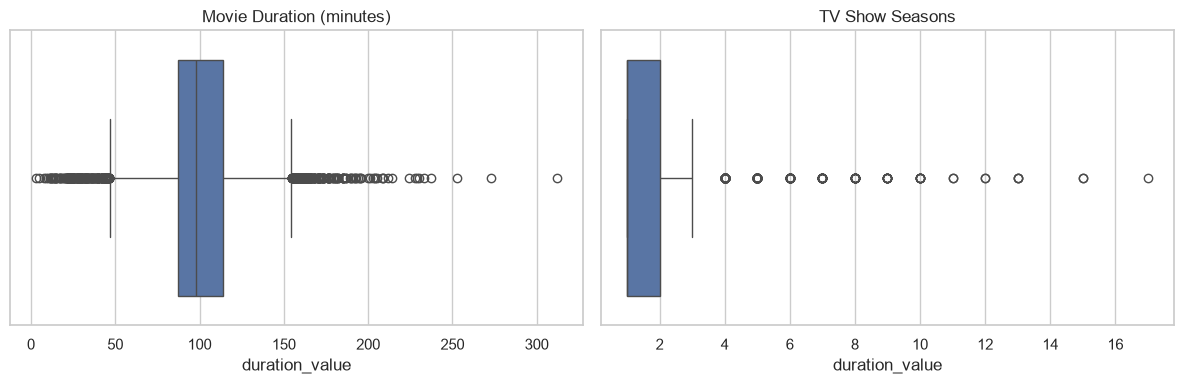

Movie-duration IQR bounds: 46.5 to 154.5 minutes
Movie duration values flagged by IQR: 450


In [10]:
movies = df.loc[df["duration_unit"].eq("min"), "duration_value"]
tv = df.loc[df["duration_unit"].eq("Seasons"), "duration_value"]

print("Movie duration (minutes) — descriptive statistics")
display(movies.describe())
print("TV show seasons — descriptive statistics")
display(tv.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=movies, ax=axes[0]); axes[0].set_title("Movie Duration (minutes)")
sns.boxplot(x=tv, ax=axes[1]); axes[1].set_title("TV Show Seasons")
plt.tight_layout(); plt.show()

# IQR flags are statistical candidates for review, not proof of data errors.
q1, q3 = movies.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
movie_outliers = movies[(movies < lower) | (movies > upper)]
print(f"Movie-duration IQR bounds: {lower:.1f} to {upper:.1f} minutes")
print("Movie duration values flagged by IQR:", len(movie_outliers))


## 6. Key findings (based on this file)

In [11]:
n = len(df)
type_pct = (df["type"].value_counts(normalize=True) * 100).round(1)
print(f"1. Movies account for {type_pct.get('Movie', 0)}% of the catalogue; TV Shows account for {type_pct.get('TV Show', 0)}%.")
print(f"2. The most frequent release year is {df['release_year'].value_counts().idxmax()} ({df['release_year'].value_counts().max()} titles).")
print(f"3. The most frequent rating label is {df['rating'].value_counts().idxmax()} ({df['rating'].value_counts().max()} titles).")
country_known = df.loc[df["country"].ne("Unknown"), "country"].value_counts()
print(f"4. The most frequent non-Unknown country-field entry is {country_known.index[0]} ({country_known.iloc[0]} titles).")
print(f"5. The median movie duration is {movies.median():.0f} minutes.")
print(f"6. The median TV show length is {tv.median():.0f} season(s).")
added_year_counts = df["year_added"].value_counts()
print(f"7. The highest number of additions occurred in {int(added_year_counts.idxmax())} ({added_year_counts.max()} titles).")
print(f"8. {df['date_added'].isna().sum()} rows have missing date_added/year_added/month_added values.")


1. Movies account for 69.6% of the catalogue; TV Shows account for 30.4%.
2. The most frequent release year is 2018 (1147 titles).
3. The most frequent rating label is TV-MA (3207 titles).
4. The most frequent non-Unknown country-field entry is United States (2819 titles).
5. The median movie duration is 98 minutes.
6. The median TV show length is 1 season(s).
7. The highest number of additions occurred in 2019 (2016 titles).
8. 10 rows have missing date_added/year_added/month_added values.


## 7. Conclusion

The dataset contains substantially more movies than TV shows. The catalogue is concentrated around releases from the late 2010s, and the most common content rating is TV-MA. The median movie runtime is about 98 minutes, while the median TV show has one season. The year-added trend peaks in 2019 in this dataset.

### Limitations
- Country values may contain multiple countries in one cell; country counts above use the raw field and can undercount individual co-production countries.
- `Unknown` is a placeholder category and should not be confused with a blank/null value.
- A statistical outlier is not automatically an incorrect record; inspect flagged titles before changing them.
- These are descriptive findings from this dataset, not proof of Netflix's current catalogue or business strategy.
